In [1]:
# Synthetic dataset for linear regression with Advertising_Spent in full thousands
dataset = {
    "Month": [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ],
    "Advertising_Spent": [12000, 15000, 14000, 17000, 18000, 21000, 22000, 21500, 20000, 17500, 16000, 15000],  # in currency units
    "Market_Index": [102, 105, 103, 108, 110, 115, 118, 117, 112, 109, 107, 104],  # index score
    "Sales": [220, 240, 230, 260, 275, 300, 720, 315, 290, 270, 255, 235]  # target variable
}
import pandas as pd
data  = pd.DataFrame(dataset)
data


,Month,Advertising_Spent,Market_Index,Sales
0,Jan,12000,102,220
1,Feb,15000,105,240
2,Mar,14000,103,230
3,Apr,17000,108,260
4,May,18000,110,275
5,Jun,21000,115,300
6,Jul,22000,118,720
7,Aug,21500,117,315
8,Sep,20000,112,290
9,Oct,17500,109,270


In [2]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
encoded = encoder.fit_transform(data[['Month']])
encoded_data = pd.DataFrame(encoded, columns = encoder.get_feature_names_out(['Month']))
final_data = pd.concat([data, encoded_data], axis=1)
print(final_data)

   Month  Advertising_Spent  Market_Index  Sales  Month_Apr  Month_Aug  \
0    Jan              12000           102    220        0.0        0.0   
1    Feb              15000           105    240        0.0        0.0   
2    Mar              14000           103    230        0.0        0.0   
3    Apr              17000           108    260        1.0        0.0   
4    May              18000           110    275        0.0        0.0   
5    Jun              21000           115    300        0.0        0.0   
6    Jul              22000           118    720        0.0        0.0   
7    Aug              21500           117    315        0.0        1.0   
8    Sep              20000           112    290        0.0        0.0   
9    Oct              17500           109    270        0.0        0.0   
10   Nov              16000           107    255        0.0        0.0   
11   Dec              15000           104    235        0.0        0.0   

    Month_Dec  Month_Feb  Month_Jan  

In [3]:
x = data[["Advertising_Spent"]]
y = data["Sales"]
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.03]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Advertising_Spent']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-163.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


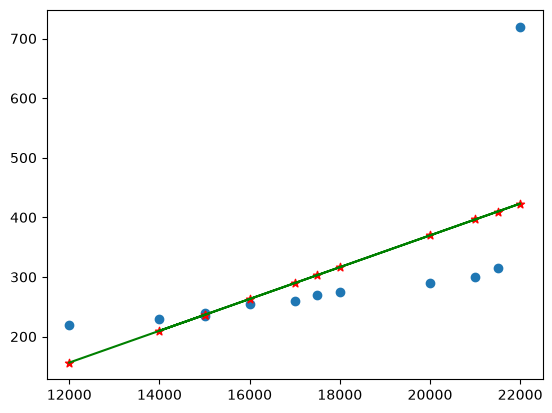

In [4]:
import matplotlib.pyplot as plt
plt.scatter(x,y)
plt.scatter(x,model.predict(x), color = 'red', marker = "*", label = "Predicted points" )
plt.plot(x,model.predict(x), color = 'green', label = " Linear regresssion ")

In [5]:
import numpy as np
q1 = np.percentile(data['Sales'],25)
q2 = np.percentile(data['Sales'],75)
iqr = q2 - q1
lower = q1 - 1.5 * iqr
print(lower)
upper = q2 + 1.5 * iqr
print(upper)
outliers = [i for i in data['Sales'] if i < lower or i > upper]
print(f"Outliers : {outliers}")


158.125
373.125
Outliers : [720]


In [6]:
model.score(x,y)

0.3978790486299848

In [7]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.2, random_state=42)

print(" total number of records in x_train :", len(x_train))
print(" total number of records in x_test :", len(x_test))
print(" total number of records in y_train :", len(y_train))
print(" total number of records in y_test :", len(y_test))


 total number of records in x_train : 9
 total number of records in x_test : 3
 total number of records in y_train : 9
 total number of records in y_test : 3


In [8]:
model = LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.03]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Advertising_Spent']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-250.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


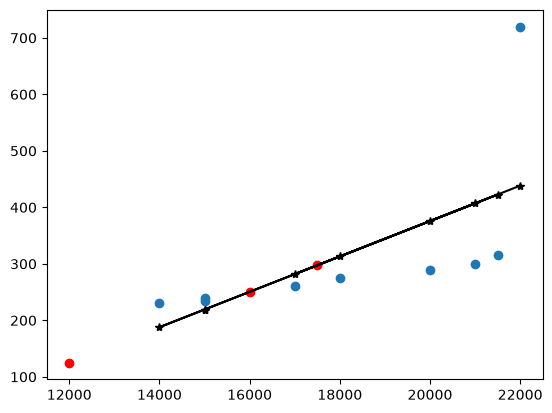

In [9]:
plt.scatter(x_train,y_train)
plt.scatter(x_test,model.predict(x_test),color='red')
plt.plot(x_train,model.predict(x_train), color = 'black', marker = "*")

In [10]:
x_test

,Advertising_Spent
10,16000
9,17500
0,12000


In [ ]:
q1 = np.percentile(y_test, 25)
q2 = np.percentile(y_test, 75)
iqr = q2 - q1
lower = q1 - 1.5 * iqr
upper = q2 + 1.5 * iqr

outliers = [i for i in y_test if i < lower or i > upper]

data = np.clip(data['ales'],lower,upper)
data



[]


KeyError: 'Sales'